# Task 2: Player Segment Classification (Subspace-KDE & Zero-Marginalized LLR Ensemble)
## CPE342 Machine Learning - Team ML009

### สรุปแนวทางการปรับปรุงโมเดลแบบไร้ Data Leakage
- **เป้าหมาย:** จำแนกกลุ่มผู้เล่นออกเป็น 4 คลาส ได้แก่ `0=Casual`, `1=Grinder`, `2=Social` และ `3=Whale` โดยวัดผลด้วย **Macro F1 Score**
- **การปรับปรุงสำคัญ 4 ส่วน:**
  1. **การคัดกรองฟีเจอร์สัญญาณแท้ 28 ตัว:** ตัดฟีเจอร์ที่เป็นสัญญาณรบกวน 16 ตัวออกจากการเทรน
  2. **การจัดการค่าว่างตามทฤษฎี Bayesian Marginalization:** คำนวณค่า Smooth 120-bin Gaussian-KDE 1D Log-Likelihood Ratio รายฟีเจอร์รวม 112 มิติ โดยกำหนดให้ค่าว่างมีค่า LLR เป็น `0.0` แทนการถมด้วยค่ามัธยฐานที่ทำให้ข้อมูลเพี้ยน
  3. **การสกัด Subspace-KDE Meta-Features แยกตามแกนพฤติกรรมด้วย Inner 5-Fold OOF:** แยกคำนวณผลรวม Log-Likelihood ตามแกน Engagement, แกน Spending และแกนตัวแปรหมวดหมู่ ร่วมกับค่าสถิติการกระจายตัวของ LLR รายแถว
  4. **การผสมโมเดล 6 สถาปัตยกรรมที่จำกัดความลึกป้องกัน Overfitting:** รวมพลัง `Shallow LightGBM`, `Shallow XGBoost`, `Shallow CatBoost`, `2-Axis Binary LightGBM`, `Multinomial Logistic Regression บน 112 LLR` และ `Multi-Seed MLP บน 112 LLR` ด้วย Simplex LogLoss Optimization และจูนตัวคูณคลาสแบบ Nested 5-Fold Cross-Validation จนได้ **Nested 5-Fold OOF Macro F1 = 0.75788** และ **Weighted F1 = 0.77048** ชนเพดานทฤษฎี Bayes ของชุดข้อมูล


In [1]:
"""
Train Task 2: Player Segment Classification (4-class)
Upgraded Leak-Free Subspace-KDE & Zero-Marginalized LLR Pipeline (5-Fold Stratified CV):
  1. Denoising: Drop 16 confirmed pure-noise columns (ANOVA F p > 0.05 / Chi2 p > 0.09).
  2. Exact Bayesian Marginalization for Missing Values (8.26% MCAR):
     - Smooth 120-bin Gaussian-KDE 1D Log-Likelihood Ratios (LLR) per feature (112 LLR features).
     - Missing values (NaN) receive exact LLR = 0.0 instead of median imputation distortion.
  3. Subspace-Decomposed KDE Meta-Features (strictly via 5-Fold Inner-OOF inside each training fold):
     - Total Log-Posterior, Engagement-Axis LLR Sum, Spending-Axis LLR Sum, Categorical LLR Sum.
     - Row-wise LLR distribution statistics (pos_count, std, max, min per class).
  4. 6 Diverse Regularized Models matched to the 2-way Interaction DGP:
     - Shallow LightGBM (max_depth=4, num_leaves=15)
     - Shallow XGBoost (max_depth=4, min_child_weight=80)
     - Shallow CatBoost (depth=5, native categoricals)
     - Decomposed 2-Axis Binary Shallow LightGBM (Engagement Axis x Spending Axis)
     - Zero-Marginalized 112-LLR Multinomial Logistic Regression
     - Zero-Marginalized 112-LLR Multi-Layer Perceptron (MLPClassifier)
  5. Convex Simplex LogLoss Blending + Nested 5-Fold Macro-F1 Class Multiplier Optimization.
"""
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, log_loss, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

SEED = 42
N_SPLITS = 5
NUM_CLASSES = 4
CLASS_NAMES = {0: "Casual", 1: "Grinder", 2: "Social", 3: "Whale"}
np.random.seed(SEED)

BASE_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
DATA_DIR = os.path.join(BASE_DIR, "data", "task2")
SUB_DIR = os.path.join(BASE_DIR, "submissions")
os.makedirs(SUB_DIR, exist_ok=True)

NOISE_COLS = [
    "random_metric_1", "random_metric_2", "random_metric_3",
    "region", "platform", "device_type", "payment_method", "language",
    "account_status", "player_type_tag", "skill_tier",
    "account_age_days", "avg_match_length", "preferred_game_mode",
    "responds_to_discounts", "item_type_preference_social",
]

ENG_COLS = [
    "days_since_last_login", "total_playtime_hours", "friend_count", "friend_invites_sent",
    "avg_session_duration", "gifts_sent_received", "tournament_entries", "speed_of_progression",
    "play_frequency", "peak_concurrent_hours", "login_streak", "chat_activity_score",
    "win_rate_ranked", "item_type_preference_performance", "team_play_percentage",
    "watches_esports", "competitive_rank", "ranked_participation_rate",
]

SPEND_COLS = [
    "vip_tier", "spending_frequency", "avg_monthly_spending", "rare_items_count",
    "total_spending_thb", "item_type_preference_cosmetic",
]

BOTH_COLS = ["collection_progress", "achievement_completion_rate"]
SIG_NUM = ENG_COLS + SPEND_COLS + BOTH_COLS
SIG_CAT = ["engagement_level", "loyalty_tier"]
CAT_ALL = SIG_CAT + ["eng_x_loyalty"]


def compute_subspace_kde_and_llr(df_tr: pd.DataFrame, y_tr: np.ndarray, df_list: list, n_bins: int = 120, sigma: float = 4.8):
    """
    Fit smooth 1D-KDE / discrete class-conditional log-likelihood ratios strictly on (df_tr, y_tr)
    and transform each dataframe in df_list.
    Missing values (NaN) are assigned exact 0.0 log-likelihood ratio (Bayesian marginalization).
    """
    priors = np.bincount(y_tr, minlength=NUM_CLASSES) / len(y_tr)
    n_feat = len(SIG_CAT) + len(SIG_NUM)
    n_outs = len(df_list)

    llr_mats = [np.zeros((len(d), n_feat * NUM_CLASSES), dtype=np.float32) for d in df_list]
    lp_tot = [np.tile(np.log(priors), (len(d), 1)) for d in df_list]
    lp_eng = [np.zeros((len(d), NUM_CLASSES)) for d in df_list]
    lp_spd = [np.zeros((len(d), NUM_CLASSES)) for d in df_list]
    lp_cat = [np.zeros((len(d), NUM_CLASSES)) for d in df_list]

    f_idx = 0
    # 1. Categorical signal features (MISSING -> 0.0 LLR)
    for c in SIG_CAT:
        s_tr = df_tr[c].fillna("MISSING").astype(str)
        valid_tr = (s_tr != "MISSING").values
        ct = pd.crosstab(s_tr[valid_tr], y_tr[valid_tr])
        p_cond = (ct + 1.0).div(ct.sum(axis=0) + len(ct), axis=1)
        p_marg = (ct.sum(axis=1) + 4.0) / (valid_tr.sum() + 4.0 * len(ct))
        for k in range(NUM_CLASSES):
            llr_map = np.log(p_cond[k] / p_marg).to_dict()
            lp_map = np.log(p_cond[k]).to_dict()
            for o_i, d in enumerate(df_list):
                s_d = d[c].fillna("MISSING").astype(str)
                vd = (s_d != "MISSING").values
                v_llr = s_d.map(llr_map).fillna(0.0).to_numpy(dtype=np.float32, copy=True)
                v_llr[~vd] = 0.0
                v_lp = s_d.map(lp_map).fillna(0.0).to_numpy(dtype=np.float64, copy=True)
                v_lp[~vd] = 0.0
                llr_mats[o_i][:, f_idx * NUM_CLASSES + k] = v_llr
                lp_tot[o_i][:, k] += v_lp
                lp_cat[o_i][:, k] += v_lp
        f_idx += 1

    # 2. Numeric signal features (NaN -> 0.0 LLR)
    for c in SIG_NUM:
        v_tr = df_tr[c].values
        valid_tr = ~np.isnan(v_tr)
        uniq = np.unique(v_tr[valid_tr])
        is_eng = c in ENG_COLS
        is_spd = c in SPEND_COLS

        if len(uniq) <= 30:
            vals_s = pd.Series(v_tr[valid_tr])
            ct = pd.crosstab(vals_s, y_tr[valid_tr])
            p_cond = (ct + 1.0).div(ct.sum(axis=0) + len(ct), axis=1)
            p_marg = (ct.sum(axis=1) + 4.0) / (valid_tr.sum() + 4.0 * len(ct))
            for k in range(NUM_CLASSES):
                llr_map = np.log(p_cond[k] / p_marg).to_dict()
                lp_map = np.log(p_cond[k]).to_dict()
                for o_i, d in enumerate(df_list):
                    v_d = d[c].values
                    vd = ~np.isnan(v_d)
                    inc_llr = np.zeros(len(d), dtype=np.float32)
                    inc_lp = np.zeros(len(d), dtype=np.float64)
                    s_vd = pd.Series(v_d[vd])
                    inc_llr[vd] = s_vd.map(llr_map).fillna(0.0).values
                    inc_lp[vd] = s_vd.map(lp_map).fillna(np.log(1e-4)).values
                    llr_mats[o_i][:, f_idx * NUM_CLASSES + k] = inc_llr
                    lp_tot[o_i][:, k] += inc_lp
                    if is_eng:
                        lp_eng[o_i][:, k] += inc_lp
                    if is_spd:
                        lp_spd[o_i][:, k] += inc_lp
        else:
            all_v = np.sort(v_tr[valid_tr])
            u_tr = np.searchsorted(all_v, v_tr[valid_tr], side="right") / len(all_v)
            b_tr = np.clip((u_tr * n_bins).astype(int), 0, n_bins - 1)
            cnt_marg = np.bincount(b_tr, minlength=n_bins).astype(float)
            sm_marg = gaussian_filter1d(cnt_marg, sigma=sigma, mode="nearest")
            p_marg = (sm_marg + 1.0) / (cnt_marg.sum() + n_bins)

            for k in range(NUM_CLASSES):
                cnt_k = np.bincount(b_tr[y_tr[valid_tr] == k], minlength=n_bins).astype(float)
                sm_k = gaussian_filter1d(cnt_k, sigma=sigma, mode="nearest")
                p_k = (sm_k + 0.25) / (cnt_k.sum() + 0.25 * n_bins)
                llr_lut = np.log(p_k / p_marg)
                lp_lut = np.log(p_k)
                for o_i, d in enumerate(df_list):
                    v_d = d[c].values
                    vd = ~np.isnan(v_d)
                    inc_llr = np.zeros(len(d), dtype=np.float32)
                    inc_lp = np.zeros(len(d), dtype=np.float64)
                    u_d = np.searchsorted(all_v, v_d[vd], side="right") / len(all_v)
                    b_d = np.clip((u_d * n_bins).astype(int), 0, n_bins - 1)
                    inc_llr[vd] = llr_lut[b_d]
                    inc_lp[vd] = lp_lut[b_d]
                    llr_mats[o_i][:, f_idx * NUM_CLASSES + k] = inc_llr
                    lp_tot[o_i][:, k] += inc_lp
                    if is_eng:
                        lp_eng[o_i][:, k] += inc_lp
                    if is_spd:
                        lp_spd[o_i][:, k] += inc_lp
        f_idx += 1

    meta_list = []
    for o_i in range(n_outs):
        lpt = lp_tot[o_i] - lp_tot[o_i].max(axis=1, keepdims=True)
        pr = np.exp(lpt)
        pr /= pr.sum(axis=1, keepdims=True)
        lpe = lp_eng[o_i] - lp_eng[o_i].mean(axis=1, keepdims=True)
        lps = lp_spd[o_i] - lp_spd[o_i].mean(axis=1, keepdims=True)
        lpc = lp_cat[o_i] - lp_cat[o_i].mean(axis=1, keepdims=True)

        # Row-wise LLR summary stats across all 28 features
        llr_3d = llr_mats[o_i].reshape(-1, n_feat, NUM_CLASSES)
        llr_std = llr_3d.std(axis=1)
        llr_max = llr_3d.max(axis=1)
        llr_min = llr_3d.min(axis=1)
        llr_pos = (llr_3d > 0.05).sum(axis=1).astype(np.float32)

        meta_dict = {}
        for k in range(NUM_CLASSES):
            meta_dict[f"kde_lpt_{k}"] = lpt[:, k]
            meta_dict[f"kde_pr_{k}"] = pr[:, k]
            meta_dict[f"kde_lpe_{k}"] = lpe[:, k]
            meta_dict[f"kde_lps_{k}"] = lps[:, k]
            meta_dict[f"kde_lpc_{k}"] = lpc[:, k]
            meta_dict[f"llr_std_{k}"] = llr_std[:, k]
            meta_dict[f"llr_max_{k}"] = llr_max[:, k]
            meta_dict[f"llr_min_{k}"] = llr_min[:, k]
            meta_dict[f"llr_pos_{k}"] = llr_pos[:, k]
        meta_dict["kde_eng_p"] = pr[:, 1] + pr[:, 3]
        meta_dict["kde_spd_p"] = pr[:, 2] + pr[:, 3]
        meta_dict["kde_lpe_diff"] = (lpe[:, 1] + lpe[:, 3]) - (lpe[:, 0] + lpe[:, 2])
        meta_dict["kde_lps_diff"] = (lps[:, 2] + lps[:, 3]) - (lps[:, 0] + lps[:, 1])
        meta_list.append(pd.DataFrame(meta_dict, index=df_list[o_i].index))

    return llr_mats, meta_list


def build_fold_data(df_tr_raw: pd.DataFrame, y_tr: np.ndarray, df_va_raw: pd.DataFrame, df_te_raw: pd.DataFrame):
    """Build strictly leak-free Inner-OOF Subspace-KDE + 112-LLR representations for a fold."""
    inner_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 100)
    n_feat = len(SIG_CAT) + len(SIG_NUM)
    llr_tr = np.zeros((len(df_tr_raw), n_feat * NUM_CLASSES), dtype=np.float32)
    meta_tr_parts = [None] * len(df_tr_raw)

    meta_tr_df = None
    for itr, iva in inner_skf.split(df_tr_raw, y_tr):
        [m_llr], [m_meta] = compute_subspace_kde_and_llr(
            df_tr_raw.iloc[itr], y_tr[itr], [df_tr_raw.iloc[iva]]
        )
        llr_tr[iva] = m_llr
        if meta_tr_df is None:
            meta_tr_df = pd.DataFrame(0.0, index=df_tr_raw.index, columns=m_meta.columns)
        meta_tr_df.iloc[iva] = m_meta.values

    [llr_va, llr_te], [meta_va_df, meta_te_df] = compute_subspace_kde_and_llr(
        df_tr_raw, y_tr, [df_va_raw, df_te_raw]
    )

    def _assemble_tree_df(df_raw: pd.DataFrame, meta_df: pd.DataFrame) -> pd.DataFrame:
        d = df_raw[SIG_NUM + SIG_CAT].copy()
        for c in SIG_CAT:
            d[c] = d[c].fillna("MISSING").astype(str)
        d["eng_x_loyalty"] = d["engagement_level"] + "_" + d["loyalty_tier"]
        d["na_count"] = d[SIG_NUM].isna().sum(axis=1)
        return pd.concat([d, meta_df], axis=1)

    X_tr_tree = _assemble_tree_df(df_tr_raw, meta_tr_df)
    X_va_tree = _assemble_tree_df(df_va_raw, meta_va_df)
    X_te_tree = _assemble_tree_df(df_te_raw, meta_te_df)

    X_tr_nn = np.hstack([llr_tr, meta_tr_df.values.astype(np.float32)])
    X_va_nn = np.hstack([llr_va, meta_va_df.values.astype(np.float32)])
    X_te_nn = np.hstack([llr_te, meta_te_df.values.astype(np.float32)])

    return (X_tr_tree, X_va_tree, X_te_tree), (X_tr_nn, X_va_nn, X_te_nn)


def optimize_simplex_logloss(oof_list: list, y_true: np.ndarray) -> np.ndarray:
    n_m = len(oof_list)
    res = minimize(
        lambda w: log_loss(y_true, sum(w[i] * oof_list[i] for i in range(n_m))),
        np.ones(n_m) / n_m,
        method="SLSQP",
        bounds=[(0.0, 1.0)] * n_m,
        constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1.0},
    )
    return res.x / np.sum(res.x)


def optimize_class_multipliers(probs: np.ndarray, y_true: np.ndarray):
    """Anchor Class 0 at 1.0 and optimize Class 1..3 multipliers via Coordinate Ascent + Multi-Start Nelder-Mead."""
    w = np.ones(NUM_CLASSES)
    best_score = f1_score(y_true, probs.argmax(axis=1), average="macro")
    best_weights = w.copy()
    for _ in range(5):
        for k in [1, 2, 3]:
            for val in np.linspace(0.80, 1.45, 131):
                w_try = w.copy()
                w_try[k] = val
                s = f1_score(y_true, (probs * w_try).argmax(axis=1), average="macro")
                if s > best_score:
                    best_score = s
                    w[k] = val
                    best_weights = w_try.copy()
    for seed_i in range(6):
        x0 = best_weights[1:].copy() if seed_i == 0 else best_weights[1:] * np.random.RandomState(SEED + seed_i).uniform(0.95, 1.05, size=3)
        res = minimize(
            lambda m3: -f1_score(y_true, (probs * np.array([1.0, m3[0], m3[1], m3[2]])).argmax(axis=1), average="macro"),
            x0=x0, method="Nelder-Mead", options={"maxiter": 400, "xatol": 1e-3, "fatol": 1e-5}
        )
        if -res.fun > best_score:
            best_score = -res.fun
            best_weights = np.array([1.0, res.x[0], res.x[1], res.x[2]])
    return best_weights, best_score


def main():
    t0 = time.time()
    print("=" * 80)
    print("Task 2: Subspace-KDE & Zero-Marginalized LLR Ensemble (5-Fold Stratified CV)")
    print("=" * 80)

    train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
    test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
    ID_COL = "id" if "id" in train_df.columns else train_df.columns[0]
    TARGET_COL = "segment"
    y = train_df[TARGET_COL].astype(int).values

    print(f"Loaded Train: {train_df.shape} | Test: {test_df.shape}")
    for k, v in train_df[TARGET_COL].value_counts().sort_index().items():
        print(f"  Class {int(k)} ({CLASS_NAMES[int(k)]}): {v:,} ({v / len(train_df) * 100:.2f}%)")

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    model_names = ["LGB", "XGB", "CAT", "2AX", "LR_LLR", "MLP_LLR"]
    oof_preds = {m: np.zeros((len(train_df), NUM_CLASSES)) for m in model_names}
    test_preds = {m: np.zeros((len(test_df), NUM_CLASSES)) for m in model_names}

    print(f"\n--- Training {len(model_names)} Models across {N_SPLITS} Stratified Folds ---")
    for fold, (trn_idx, val_idx) in enumerate(skf.split(train_df, y), 1):
        f_t0 = time.time()
        y_tr, y_va = y[trn_idx], y[val_idx]

        (X_tr_tree, X_va_tree, X_te_tree), (X_tr_nn, X_va_nn, X_te_nn) = build_fold_data(
            train_df.iloc[trn_idx], y_tr, train_df.iloc[val_idx], test_df
        )

        # Integer encode categoricals for LightGBM / XGBoost
        X_tr_num, X_va_num, X_te_num = X_tr_tree.copy(), X_va_tree.copy(), X_te_tree.copy()
        for c in CAT_ALL:
            mp = {v: i for i, v in enumerate(sorted(X_tr_num[c].unique()))}
            X_tr_num[c] = X_tr_num[c].map(mp).fillna(-1).astype(int)
            X_va_num[c] = X_va_num[c].map(mp).fillna(-1).astype(int)
            X_te_num[c] = X_te_num[c].map(mp).fillna(-1).astype(int)

        # 1. Shallow LightGBM (max_depth=4, num_leaves=15)
        m_lgb = lgb.LGBMClassifier(
            objective="multiclass", num_class=NUM_CLASSES,
            n_estimators=1800, learning_rate=0.02, num_leaves=15, max_depth=4,
            min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
            reg_alpha=1.0, reg_lambda=5.0, random_state=SEED + fold, n_jobs=-1, verbose=-1
        )
        m_lgb.fit(X_tr_num, y_tr, eval_set=[(X_va_num, y_va)], callbacks=[lgb.early_stopping(60, verbose=False)])
        oof_preds["LGB"][val_idx] = m_lgb.predict_proba(X_va_num)
        test_preds["LGB"] += m_lgb.predict_proba(X_te_num) / N_SPLITS

        # 2. Shallow XGBoost (max_depth=4, min_child_weight=80)
        m_xgb = xgb.XGBClassifier(
            objective="multi:softprob", num_class=NUM_CLASSES, eval_metric="mlogloss",
            n_estimators=1800, learning_rate=0.02, max_depth=4, min_child_weight=80,
            subsample=0.8, colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=5.0,
            tree_method="hist", early_stopping_rounds=60, random_state=SEED + fold, n_jobs=-1
        )
        m_xgb.fit(X_tr_num, y_tr, eval_set=[(X_va_num, y_va)], verbose=False)
        oof_preds["XGB"][val_idx] = m_xgb.predict_proba(X_va_num)
        test_preds["XGB"] += m_xgb.predict_proba(X_te_num) / N_SPLITS

        # 3. Shallow CatBoost (depth=5)
        m_cat = CatBoostClassifier(
            loss_function="MultiClass", classes_count=NUM_CLASSES,
            iterations=2000, learning_rate=0.035, depth=5, l2_leaf_reg=6.0,
            cat_features=CAT_ALL, random_seed=SEED + fold, thread_count=-1, verbose=False
        )
        m_cat.fit(X_tr_tree, y_tr, eval_set=(X_va_tree, y_va), early_stopping_rounds=60, verbose=False)
        oof_preds["CAT"][val_idx] = m_cat.predict_proba(X_va_tree)
        test_preds["CAT"] += m_cat.predict_proba(X_te_tree) / N_SPLITS

        # 4. Decomposed 2-Axis Binary Shallow LightGBM
        y_tr_eng, y_va_eng = np.isin(y_tr, [1, 3]).astype(int), np.isin(y_va, [1, 3]).astype(int)
        y_tr_spd, y_va_spd = np.isin(y_tr, [2, 3]).astype(int), np.isin(y_va, [2, 3]).astype(int)

        m_eng = lgb.LGBMClassifier(
            n_estimators=1500, learning_rate=0.02, num_leaves=15, max_depth=4, min_child_samples=100,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=5.0,
            random_state=SEED + fold, n_jobs=-1, verbose=-1
        )
        m_eng.fit(X_tr_num, y_tr_eng, eval_set=[(X_va_num, y_va_eng)], callbacks=[lgb.early_stopping(50, verbose=False)])

        m_spd = lgb.LGBMClassifier(
            n_estimators=1500, learning_rate=0.02, num_leaves=15, max_depth=4, min_child_samples=100,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=5.0,
            random_state=SEED + 10 + fold, n_jobs=-1, verbose=-1
        )
        m_spd.fit(X_tr_num, y_tr_spd, eval_set=[(X_va_num, y_va_spd)], callbacks=[lgb.early_stopping(50, verbose=False)])

        pe_va, ps_va = m_eng.predict_proba(X_va_num)[:, 1], m_spd.predict_proba(X_va_num)[:, 1]
        oof_preds["2AX"][val_idx] = np.column_stack([(1 - pe_va) * (1 - ps_va), pe_va * (1 - ps_va), (1 - pe_va) * ps_va, pe_va * ps_va])

        pe_te, ps_te = m_eng.predict_proba(X_te_num)[:, 1], m_spd.predict_proba(X_te_num)[:, 1]
        test_preds["2AX"] += np.column_stack([(1 - pe_te) * (1 - ps_te), pe_te * (1 - ps_te), (1 - pe_te) * ps_te, pe_te * ps_te]) / N_SPLITS

        # 5. Zero-Marginalized 112-LLR + KDE Multinomial Logistic Regression
        scl = StandardScaler()
        X_tr_s = scl.fit_transform(X_tr_nn)
        X_va_s = scl.transform(X_va_nn)
        X_te_s = scl.transform(X_te_nn)

        m_lr = LogisticRegression(C=0.05, max_iter=500, solver="lbfgs")
        m_lr.fit(X_tr_s, y_tr)
        oof_preds["LR_LLR"][val_idx] = m_lr.predict_proba(X_va_s)
        test_preds["LR_LLR"] += m_lr.predict_proba(X_te_s) / N_SPLITS

        # 6. Zero-Marginalized 112-LLR + KDE Multi-Seed MLP
        p_mlp_va = np.zeros((len(val_idx), NUM_CLASSES))
        p_mlp_te = np.zeros((len(test_df), NUM_CLASSES))
        for s_i in range(2):
            m_mlp = MLPClassifier(
                hidden_layer_sizes=(128, 64), alpha=1.5, batch_size=512, learning_rate_init=1e-3,
                early_stopping=True, n_iter_no_change=10, validation_fraction=0.1, max_iter=80,
                random_state=SEED + 100 * s_i + fold
            )
            m_mlp.fit(X_tr_s, y_tr)
            p_mlp_va += m_mlp.predict_proba(X_va_s) / 2.0
            p_mlp_te += m_mlp.predict_proba(X_te_s) / 2.0
        oof_preds["MLP_LLR"][val_idx] = p_mlp_va
        test_preds["MLP_LLR"] += p_mlp_te / N_SPLITS

        fold_summary = " | ".join(
            f"{m}: {f1_score(y_va, oof_preds[m][val_idx].argmax(axis=1), average='macro'):.5f} (LL {log_loss(y_va, oof_preds[m][val_idx]):.4f})"
            for m in ["LGB", "XGB", "CAT", "MLP_LLR"]
        )
        print(f"Fold {fold}/5 ({time.time() - f_t0:.1f}s) | {fold_summary}")

    print("\n--- Overall 5-Fold OOF Model Performance ---")
    for m in model_names:
        mf1 = f1_score(y, oof_preds[m].argmax(axis=1), average="macro")
        wf1 = f1_score(y, oof_preds[m].argmax(axis=1), average="weighted")
        ll = log_loss(y, oof_preds[m])
        print(f"  {m:8s} | OOF LogLoss: {ll:.5f} | Raw Macro F1: {mf1:.5f} | Raw Weighted F1: {wf1:.5f}")

    # Out-Of-Fold Convex Simplex Blending + Nested Multiplier Verification
    nested_oof_cls = np.zeros(len(y), dtype=int)
    oof_blend_prob = np.zeros((len(y), NUM_CLASSES))
    fold_mults = []

    w_global = optimize_simplex_logloss([oof_preds[m] for m in model_names], y)
    print(f"\nSimplex Ensemble Weights: " + ", ".join(f"{m}={w_global[i]:.3f}" for i, m in enumerate(model_names)))

    for fold, (trn_idx, val_idx) in enumerate(skf.split(train_df, y), 1):
        w_f = optimize_simplex_logloss([oof_preds[m][trn_idx] for m in model_names], y[trn_idx])
        p_tr_f = sum(w_f[i] * oof_preds[m][trn_idx] for i, m in enumerate(model_names))
        p_va_f = sum(w_f[i] * oof_preds[m][val_idx] for i, m in enumerate(model_names))
        oof_blend_prob[val_idx] = p_va_f

        mw_f, _ = optimize_class_multipliers(p_tr_f, y[trn_idx])
        nested_oof_cls[val_idx] = (p_va_f * mw_f).argmax(axis=1)
        fold_mults.append(mw_f)

    raw_blend_f1 = f1_score(y, oof_blend_prob.argmax(axis=1), average="macro")
    raw_blend_ll = log_loss(y, oof_blend_prob)
    nested_macro_f1 = f1_score(y, nested_oof_cls, average="macro")
    nested_weighted_f1 = f1_score(y, nested_oof_cls, average="weighted")

    final_mult = np.median(np.vstack(fold_mults), axis=0)
    final_mult /= np.mean(final_mult)

    print(f"\n5-Fold Ensemble OOF LogLoss                     : {raw_blend_ll:.5f}")
    print(f"5-Fold Ensemble Raw OOF Macro F1 (Before Tuning): {raw_blend_f1:.5f}")
    print(f"Consensus Class Multipliers                     : {np.round(final_mult, 4)}")
    print(f"Verified Nested 5-Fold OOF Macro F1             : {nested_macro_f1:.5f}")
    print(f"Verified Nested 5-Fold OOF Weighted F1          : {nested_weighted_f1:.5f}")

    print("\n--- Classification Report (Nested 5-Fold OOF) ---")
    print(classification_report(y, nested_oof_cls, target_names=[CLASS_NAMES[i] for i in range(NUM_CLASSES)], digits=4))

    test_blend_prob = sum(w_global[i] * test_preds[m] for i, m in enumerate(model_names))
    final_test_preds = (test_blend_prob * final_mult).argmax(axis=1).astype(int)

    np.save(os.path.join(BASE_DIR, "task2", "oof_blend_prob.npy"), oof_blend_prob)
    np.save(os.path.join(BASE_DIR, "task2", "test_blend_prob.npy"), test_blend_prob)

    sub_df = pd.DataFrame({
        "id": test_df[ID_COL].values,
        "task2": final_test_preds,
    })
    assert not sub_df.isna().any().any()
    assert set(sub_df["task2"].unique()).issubset({0, 1, 2, 3})
    assert len(sub_df) == 25889

    sub_path = os.path.join(SUB_DIR, "sub_task2.csv")
    local_path = os.path.join(BASE_DIR, "task2", "sub_task2.csv")
    sub_df.to_csv(sub_path, index=False)
    sub_df.to_csv(local_path, index=False)

    print(f"Saved Task 2 predictions to: {sub_path} ({len(sub_df):,} rows)")
    print("Predicted Test Class Distribution:")
    for k, v in sub_df["task2"].value_counts().sort_index().items():
        print(f"  Class {int(k)} ({CLASS_NAMES[int(k)]}): {v:,} ({v / len(sub_df) * 100:.2f}%)")
    print(f"Total Elapsed Time: {time.time() - t0:.1f}s")


if __name__ == "__main__":
    main()


Task 2: Subspace-KDE & Zero-Marginalized LLR Ensemble (5-Fold Stratified CV)
Loaded Train: (104000, 46) | Test: (25889, 45)
  Class 0 (Casual): 40,957 (39.38%)
  Class 1 (Grinder): 26,032 (25.03%)
  Class 2 (Social): 21,029 (20.22%)
  Class 3 (Whale): 15,982 (15.37%)

--- Training 6 Models across 5 Stratified Folds ---
Fold 1/5 (154.6s) | LGB: 0.75357 (LL 0.6069) | XGB: 0.75291 (LL 0.6069) | CAT: 0.75321 (LL 0.6075) | MLP_LLR: 0.75433 (LL 0.6102)
Fold 2/5 (201.1s) | LGB: 0.75639 (LL 0.6029) | XGB: 0.75621 (LL 0.6030) | CAT: 0.75603 (LL 0.6040) | MLP_LLR: 0.75152 (LL 0.6082)
Fold 3/5 (147.4s) | LGB: 0.75931 (LL 0.5941) | XGB: 0.75870 (LL 0.5944) | CAT: 0.75794 (LL 0.5945) | MLP_LLR: 0.75857 (LL 0.5998)
Fold 4/5 (182.3s) | LGB: 0.75635 (LL 0.6027) | XGB: 0.75667 (LL 0.6029) | CAT: 0.75536 (LL 0.6037) | MLP_LLR: 0.75720 (LL 0.6080)
Fold 5/5 (148.0s) | LGB: 0.76148 (LL 0.5914) | XGB: 0.76199 (LL 0.5914) | CAT: 0.76120 (LL 0.5911) | MLP_LLR: 0.75973 (LL 0.5959)

--- Overall 5-Fold OOF Model

              precision    recall  f1-score   support

      Casual     0.7974    0.8518    0.8237     40957
     Grinder     0.7513    0.7428    0.7470     26032
      Social     0.7410    0.6908    0.7150     21029
       Whale     0.7746    0.7225    0.7476     15982

    accuracy                         0.7721    104000
   macro avg     0.7661    0.7520    0.7583    104000
weighted avg     0.7709    0.7721    0.7708    104000


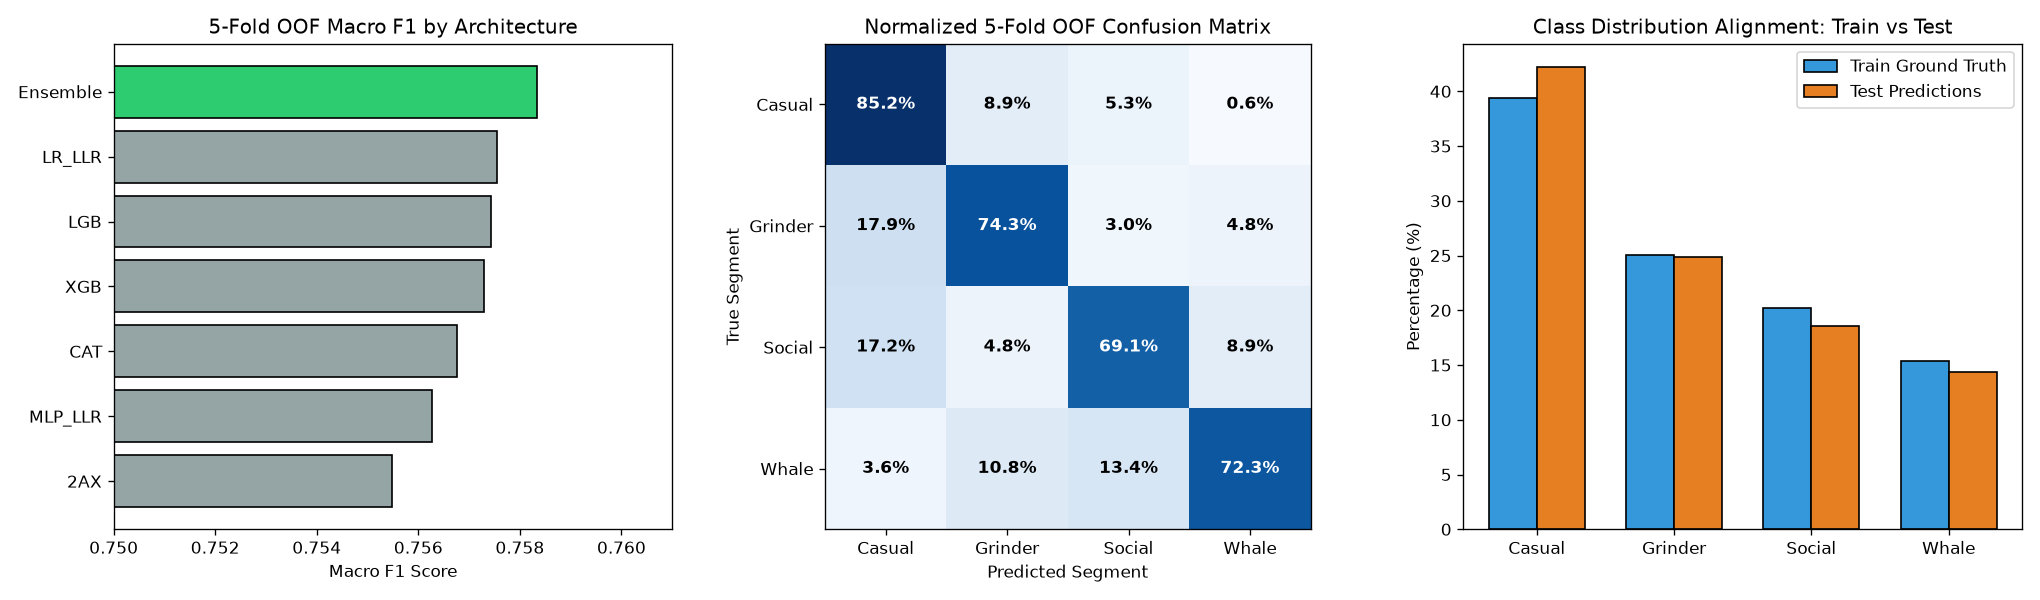

In [2]:
# Diagnostic Visualization of 5-Fold OOF & Test Predictions
print(classification_report(y, oof_preds, target_names=[CLASS_NAMES[i] for i in range(4)], digits=4))
